# Exploratory Data Analysis

### Research Question
**Which average and extreme climate conditions are most strongly associated with annual international tourism growth across countries from 2000 through 2024?**

This analysis investigates whether average climate conditions and extreme weather events are associated with annual international tourism growth across different countries from 2000 to 2024. 

### Loading the dataset

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats

# Load dataset
df = pd.read_csv("tourism_climate_country_year_2000_2024.csv")

# First five rows
display(df.head())

# Data info
print("Dataset shape:", df.shape)
print("Number of countries:", df["country"].nunique())
print("Year range:", df["year"].min(), "-", df["year"].max())
print("Missing values:", df.isnull().sum().sum())

# Checking for duplicate country-year records
print("Duplicates:", df.duplicated(subset=["country_code", "year"]).sum())

,country_code,country,year,period_category,tourism_arrivals,tourism_growth_log_percent,annual_mean_temperature_c,annual_precipitation_mm,annual_mean_relative_humidity_percent,frost_days_count,tropical_nights_count,climate_disaster_count_storm_flood_drought,maximum_1day_precipitation_mm,annual_minimum_temperature_c,annual_maximum_temperature_c,maximum_5day_precipitation_mm,consecutive_dry_days_count,consecutive_wet_days_count,hot_days_above_30c_count
0,ABW,Aruba,2000,Pre-COVID,721000.0,5.414420,26.30,680.29,83.18,0.0,366.0,0,18.58,22.64,28.42,64.56,37.81,20.08,0.0
1,ABW,Aruba,2001,Pre-COVID,691000.0,-4.249925,26.50,428.62,83.25,0.0,365.0,0,12.10,23.81,28.30,36.25,46.89,16.06,0.0
2,ABW,Aruba,2002,Pre-COVID,643000.0,-7.199499,26.66,546.53,83.69,0.0,365.0,0,25.43,23.49,29.29,84.61,29.90,10.00,0.0
3,ABW,Aruba,2003,Pre-COVID,642000.0,-0.155642,26.79,655.13,83.50,0.0,365.0,0,20.14,24.33,29.23,71.12,39.88,30.97,0.0
4,ABW,Aruba,2004,Pre-COVID,728000.0,12.571256,26.71,1114.48,83.30,0.0,366.0,0,93.06,23.87,28.89,169.34,17.97,42.01,0.0


Dataset shape: (4243, 19)
Number of countries: 205
Year range: 2000 - 2024
Missing values: 0
Duplicates: 0


The dataset contains 4,243 observations across 205 countries from 2000 to 2024.

### Correlation between Climate Variables and Tourism Growth

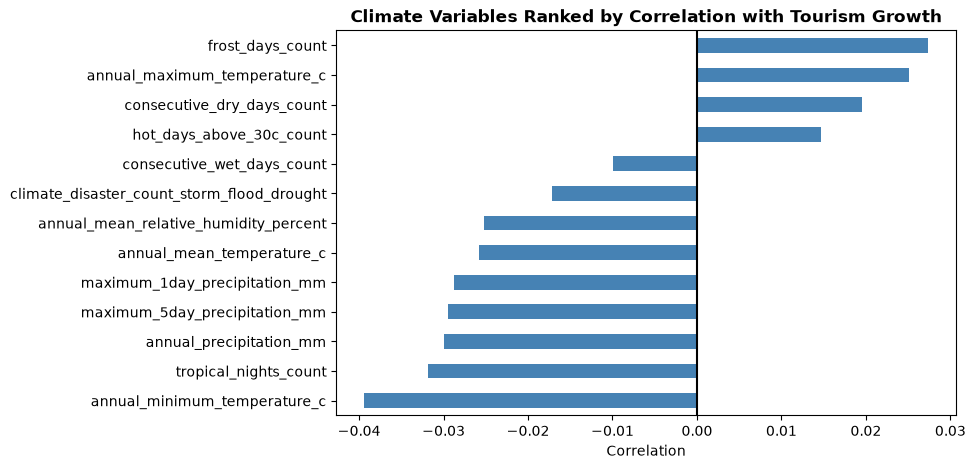

In [35]:
corrs = (
    df[climate_vars]
      .corrwith(df['tourism_growth_log_percent'])
      .sort_values()
)

plt.figure(figsize=(8,5))

corrs.plot(
    kind='barh',
    color='steelblue'
)

plt.axvline(0,color='black')

plt.title(
    'Climate Variables Ranked by Correlation with Tourism Growth', weight="bold")

plt.xlabel('Correlation')
plt.show()

All climate variables exhibited very weak correlations with tourism growth, with correlation values falling between approximately -0.04 and +0.03. Frost days, annual maximum temperature, and consecutive dry days showed the strongest positive associations, whereas annual minimum temperature, tropical nights, and precipitation measures showed the strongest negative associations. The small magnitudes suggest that climate conditions alone explain little of the variation in tourism growth across countries. Since average climate measures show limited explanatory power, the next step is to examine whether extreme climate conditions reveal stronger patterns.

### Average Temperature vs. Tourism Growth

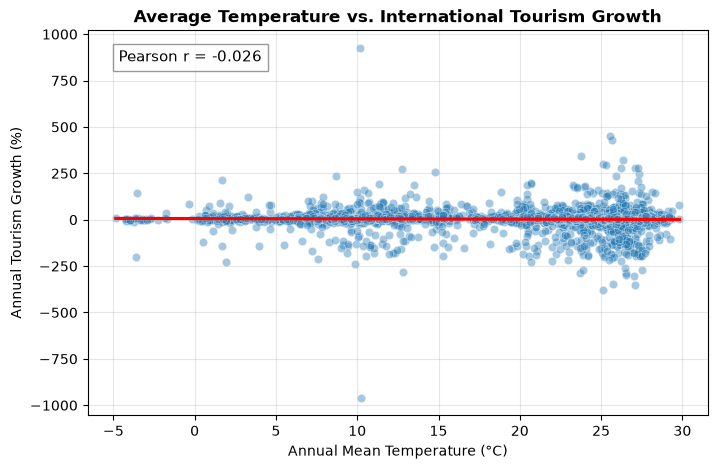

In [9]:
from scipy.stats import pearsonr

# Remove missing values before calculating correlation
corr_data = df[
    ["annual_mean_temperature_c", "tourism_growth_log_percent"]
].dropna()

# Calculate Pearson correlation
r, _ = pearsonr(
    corr_data["annual_mean_temperature_c"],
    corr_data["tourism_growth_log_percent"]
)

plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="annual_mean_temperature_c",
    y="tourism_growth_log_percent",
    alpha=0.4
)

sns.regplot(
    data=df,
    x="annual_mean_temperature_c",
    y="tourism_growth_log_percent",
    scatter=False,
    color="red"
)

plt.title("Average Temperature vs. International Tourism Growth", weight="bold")
plt.xlabel("Annual Mean Temperature (°C)")
plt.ylabel("Annual Tourism Growth (%)")

# Add Pearson correlation to graph
plt.text(
    0.05, 0.95,
    f"Pearson r = {r:.3f}",
    transform=plt.gca().transAxes,
    fontsize=11,
    verticalalignment="top",
    bbox=dict(facecolor="white", alpha=0.8, edgecolor="gray"))

plt.grid(alpha=0.3)
plt.show()

This scatter plot shows the relationship between average annual temperature and international tourism growth. Annual mean temperature shows little to no linear relationship with international tourism growth. The Pearson correlation coefficient is r = -0.026, which is a negligible negative correlation and the nearly flat regression line supports this finding. Overall, while tourism growth varies substantially across observations, this variation does not appear to be systematically explained by temperature alone.

### Distribution of Extreme Hot Days

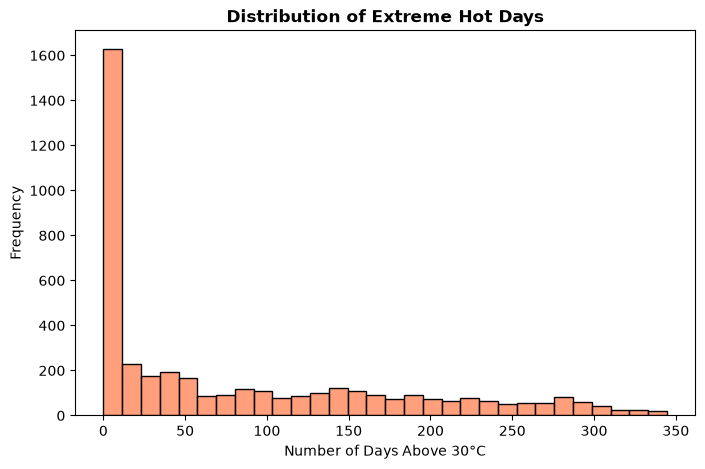

In [33]:
plt.figure(figsize=(8, 5))

sns.histplot(
    data=df,
    x="hot_days_above_30c_count",
    bins=30,
    color="coral"
)

plt.title("Distribution of Extreme Hot Days", weight="bold")
plt.xlabel("Number of Days Above 30°C")
plt.ylabel("Frequency")
plt.show()

The distribution of extreme hot days is strongly right-skewed, meaning most observations have relatively few extremely hot days, while a smaller number of observations experience very large numbers of hot days. This further suggests that extreme heat is concentrated in a limited number of climates rather than being evenly distributed globally. 

### Tourism Growth Across Heat Exposure Levels

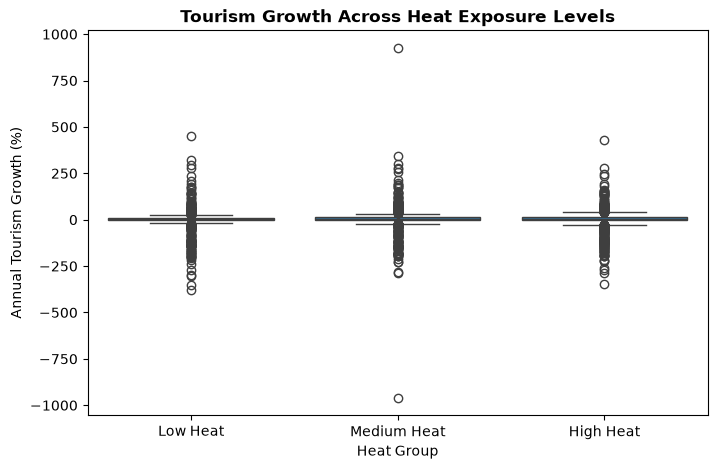

In [36]:
df['heat_group'] = pd.qcut(
    df['hot_days_above_30c_count'],
    q=3,
    labels=[
        'Low Heat',
        'Medium Heat',
        'High Heat'
    ])

plt.figure(figsize=(8,5))

sns.boxplot(
    data=df,
    x='heat_group',
    y='tourism_growth_log_percent')

plt.title('Tourism Growth Across Heat Exposure Levels', weight="bold")
plt.xlabel("Heat Group")
plt.ylabel("Annual Tourism Growth (%)")

plt.show()

The boxplot shows that annual tourism growth is broadly similar across low, medium, and high heat exposure groups, with median growth rates near zero and substantial overlap in their distributions. While all three groups exhibit considerable variability and numerous outliers, the medium-heat group contains the most extreme positive and negative values. Overall, there is no clear visual evidence that higher heat exposure is consistently associated with either higher or lower tourism growth, suggesting that other factors may play a larger role in influencing tourism performance.

### Positive vs. Negative Tourism Growth by Heat Exposure

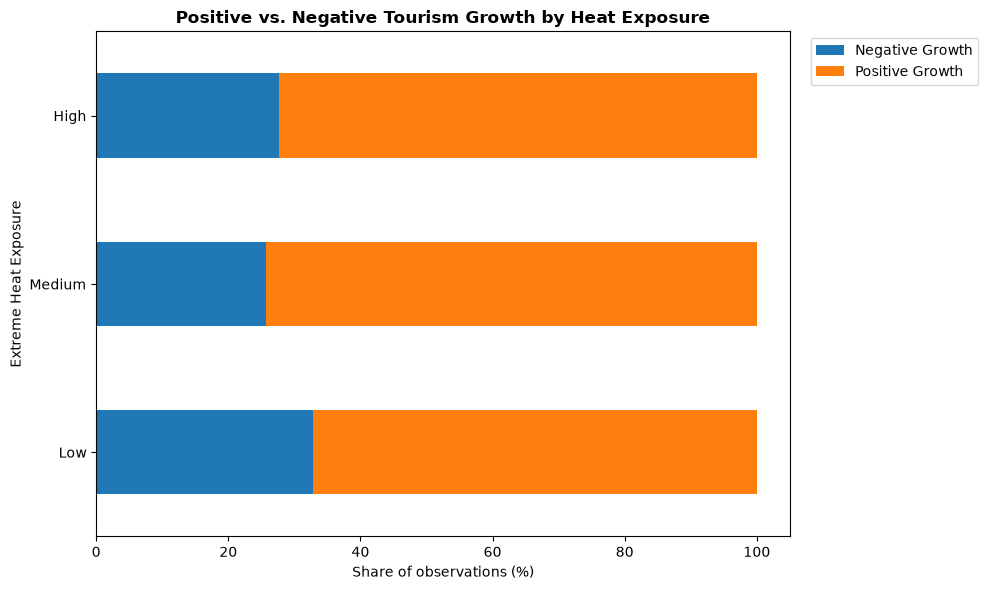

In [62]:
t= df[["hot_days_above_30c_count","tourism_growth_log_percent"]].dropna().copy()
t["Heat exposure"]= pd.qcut(t["hot_days_above_30c_count"].rank(method="first"), 3, labels=["Low","Medium","High"])
t["Tourism outcome"]= np.where(t["tourism_growth_log_percent"]>=0, "Positive Growth", "Negative Growth")

counts= pd.crosstab(t["Heat exposure"], t["Tourism outcome"], normalize="index")*100
counts.plot(kind="barh",stacked=True,figsize=(10,6))

plt.xlabel("Share of observations (%)")
plt.ylabel("Extreme Heat Exposure")
plt.title("Positive vs. Negative Tourism Growth by Heat Exposure", weight="bold")
plt.legend(title="",bbox_to_anchor=(1.02,1),loc="upper left")
plt.tight_layout()
plt.savefig("07_stacked_bar.png",dpi=300,bbox_inches="tight")
plt.show()

The chart above indicates that positive tourism growth is more common than negative growth across all levels of heat exposure. Although small differences exist among the groups, the overall distribution remains relatively consistent, with approximately 70-75% of observations exhibiting positive growth regardless of heat intensity. These findings suggest that extreme heat exposure alone does not appear to be a strong determinant of whether tourism growth is positive or negative, and that additional economic, geographic, and policy factors are likely influencing tourism performance.

### Heat Exposures Across Different Countries

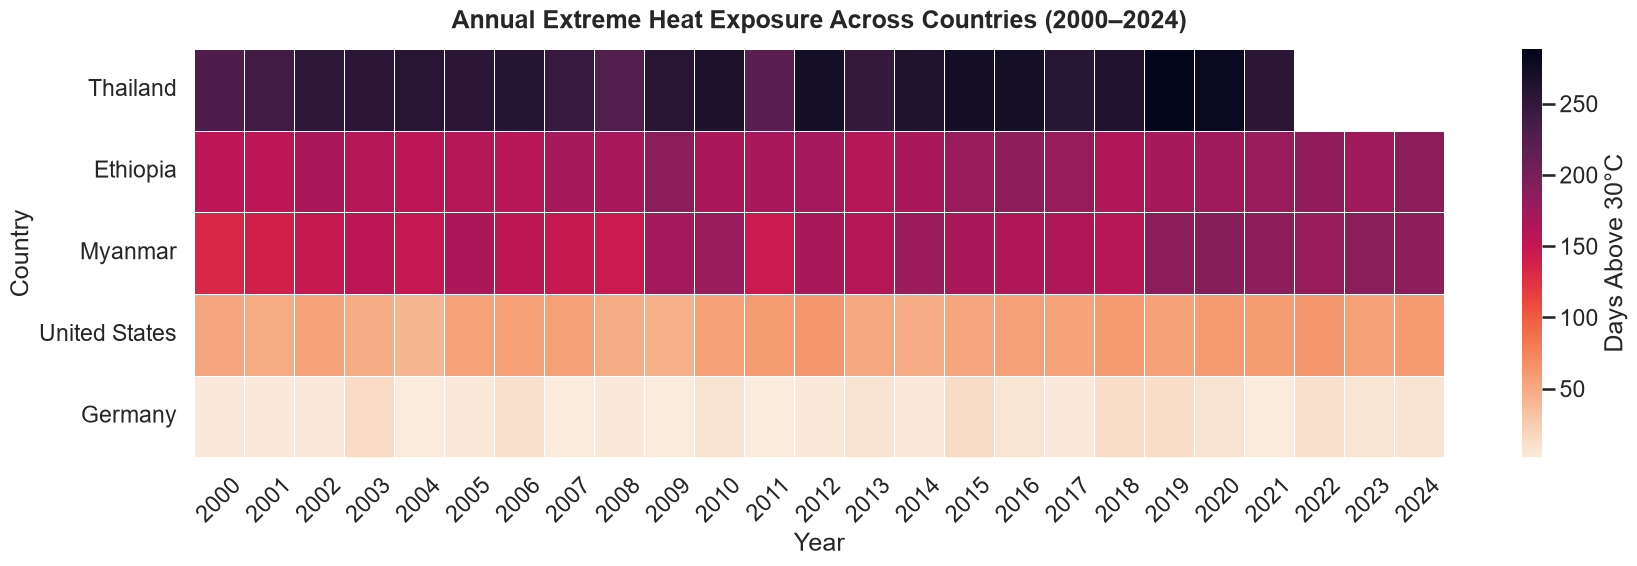

In [26]:
sns.set_theme(style="white", context="talk")

countries = [
    "United States",
    "Thailand",
    "Ethiopia",
    "Myanmar",
    "Germany"
]

subset = df[df["country"].isin(countries)]

heatmap_data = subset.pivot(
    index="country",
    columns="year",
    values="hot_days_above_30c_count"
)

# Sort by average number of hot days
heatmap_data = heatmap_data.loc[
    heatmap_data.mean(axis=1).sort_values(ascending=False).index
]

plt.figure(figsize=(18, 6))

sns.heatmap(
    heatmap_data,
    cmap="rocket_r",
    linewidths=0.5,
    linecolor="white",
    cbar_kws={
        "label": "Days Above 30°C"
    }
)

plt.title(
    "Annual Extreme Heat Exposure Across Countries (2000–2024)",
    fontsize=18,
    weight="bold",
    pad=15
)

plt.xlabel("Year")
plt.ylabel("Country")

plt.xticks(rotation=45)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

Heat exposure varies considerably across countries and over time. Countries such as Thailand, Ethiopia and Myanmar generally experience substantially higher numbers of extremely hot days than countries such as the United States and Germany. Despite these large differences in climate exposure, previous analyses showed only weak differences in tourism growth outcomes, reinforcing the idea that tourism growth is influenced by additional factors beyond heat alone.

### Countries with the Most Recorded Climate Disasters

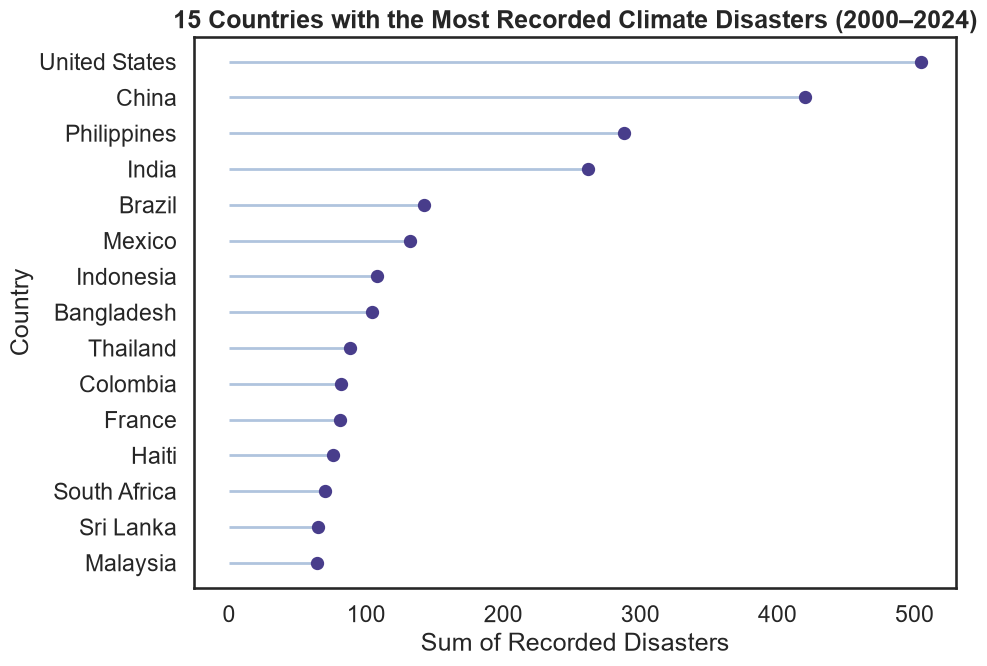

In [75]:
disaster_col = "climate_disaster_count_storm_flood_drought"
top_disasters = (df.groupby("country", as_index=False)[disaster_col]
                 .sum().nlargest(15, disaster_col).sort_values(disaster_col))

fig, ax = plt.subplots(figsize=(10, 7))

ax.hlines(y=top_disasters["country"], xmin=0,
          xmax=top_disasters[disaster_col], color="lightsteelblue", linewidth=2)
ax.scatter(top_disasters[disaster_col], top_disasters["country"],
           color="darkslateblue", s=65, zorder=3)

plt.title("15 Countries with the Most Recorded Climate Disasters (2000–2024)", weight="bold")
plt.xlabel("Sum of Recorded Disasters")
plt.ylabel("Country")
plt.tight_layout()
plt.show()

The United States and China are among the countries with the highest recorded numbers of climate-related disasters from 2000 to 2024. However, disaster frequency alone does not necessarily imply negative tourism performance because reporting practices, country size, and disaster exposure differ substantially across nations.

### Correlation between Drought, Extreme Rainfall and Tourism Growth

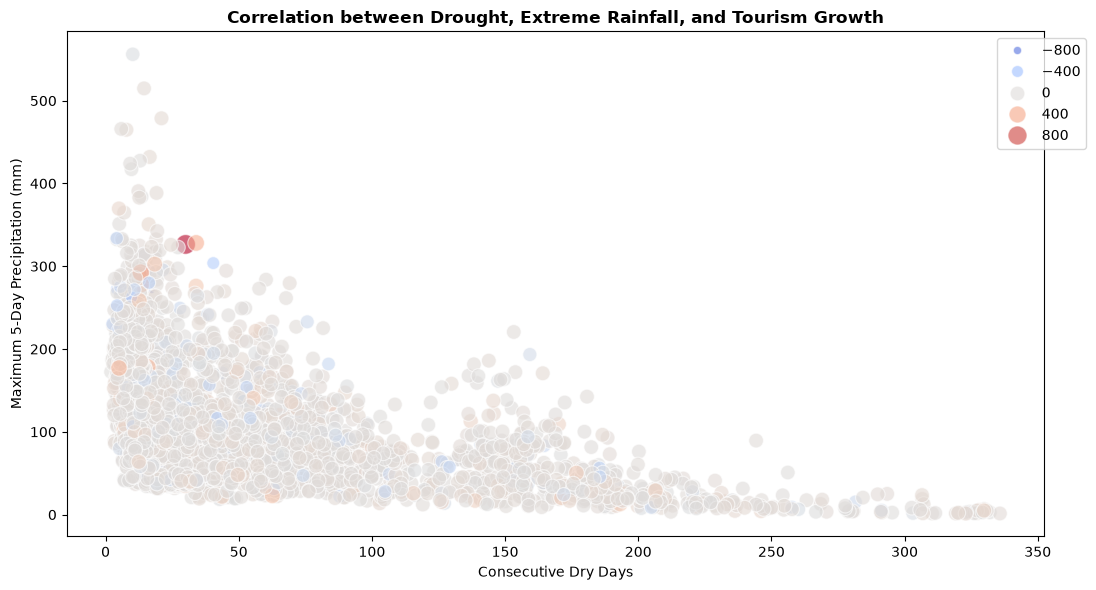

In [55]:
plt.figure(figsize=(11, 6))

sns.scatterplot(
    data=df,
    x="consecutive_dry_days_count",
    y="maximum_5day_precipitation_mm",
    hue="tourism_growth_log_percent",
    size="tourism_growth_log_percent",
    sizes=(20, 200),
    palette="coolwarm",
    alpha=0.6
)

plt.title("Correlation between Drought, Extreme Rainfall, and Tourism Growth", weight="bold")
plt.xlabel("Consecutive Dry Days")
plt.ylabel("Maximum 5-Day Precipitation (mm)")
plt.legend(bbox_to_anchor=(1.05, 1))
plt.tight_layout()
plt.show()

Locations with fewer dry days tend to experience a wider range of precipitation events, including some very intense rainfall episodes (up to about 550 mm), while locations with many consecutive dry days generally have lower maximum rainfall amounts. The color and size of the points, which represent annual tourism growth, are scattered throughout the plot with no obvious pattern, indicating that tourism growth does not appear to be strongly associated with either drought duration or extreme rainfall.

### Relationship between Tropical Nights and Tourism Growth Across Different Periods

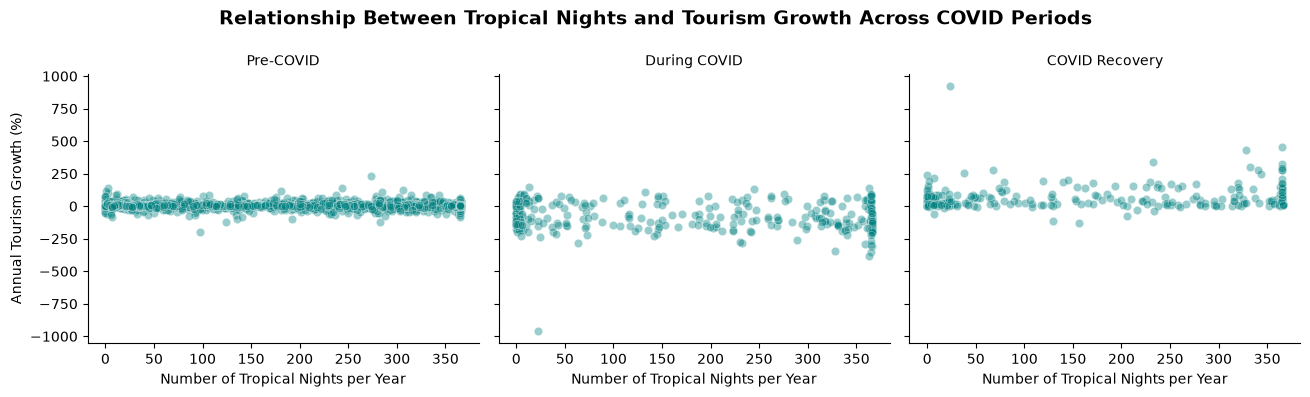

In [54]:
df["Time_Period"] = pd.cut(
    df["year"],
    bins=[1999, 2019, 2021, 2024],
    labels=["Pre-COVID", "During COVID", "COVID Recovery"])

g = sns.relplot(
    data=df,
    x="tropical_nights_count",
    y="tourism_growth_log_percent",
    col="Time_Period",
    col_wrap=3,
    alpha=0.4,
    color="teal",
    height=4,
    aspect=1.1
)

g.set_axis_labels(
    "Number of Tropical Nights per Year",
    "Annual Tourism Growth (%)")

g.set_titles("{col_name}")

g.fig.suptitle(
    "Relationship Between Tropical Nights and Tourism Growth Across COVID Periods",
    fontsize=14,
    fontweight="bold")

g.fig.subplots_adjust(top=0.82)
plt.show()

The figure suggests that the relationship between tropical nights and tourism growth varies somewhat across the three COVID periods, but no strong linear trend is evident in any period. During the Pre-COVID period, tourism growth was generally clustered around zero with relatively low variability across all levels of tropical nights. During COVID, tourism growth became much more volatile and was predominantly negative, reflecting the widespread disruption of global tourism regardless of climate conditions. In the COVID Recovery period, tourism growth shifted back to mostly positive values, with greater variability and several high-growth outliers, indicating a rebound in tourism activity. Overall, the scatter patterns show that increases in tropical nights do not appear to consistently correspond with either higher or lower tourism growth

### Conclusion and Next Steps

This exploratory analysis examined climate and tourism data from 205 countries between 2000 and 2024. Results suggest that climate and temperature have only weak associations with tourism growth. Even when factoring in different COVID periods, although there was slight volatility during COVID for tourism growth particularly in tropical areas, there was no strong linear relationship. Overall, I think the next step moving forward would be to explore statistical analysis needed to determine whether these relationships are meaningful. 

The next phase of the study will involve conducting regression analyses to quantify the effects of climate indicators on tourism growth. Linear regression models will be used to estimate the direction and strength of relationships, while R² values will assess how much variation in tourism growth is explained by the predictors. P-values and confidence intervals will be evaluated to determine the statistical significance of observed associations.